## MID Project

In [1]:
!pip install -q kagglehub scikit-learn matplotlib seaborn
import tensorflow as tf
print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---
# PART 1 – DNN: Telco Customer Churn

## 1. Load the dataset

In [29]:
import os, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub

path = kagglehub.dataset_download("blastchar/telco-customer-churn")
csv = glob.glob(os.path.join(path, "*.csv"))[0]
df = pd.read_csv(csv)
print(csv, df.shape)
df.head()

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
/kaggle/input/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Explore the data

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


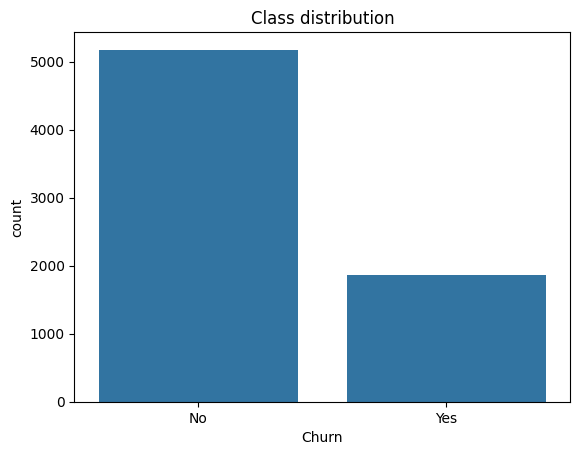

In [30]:
df.info()
print(df['Churn'].value_counts(normalize=True))
sns.countplot(x='Churn', data=df); plt.title('Class distribution'); plt.show()

TotalCharges    11
dtype: int64


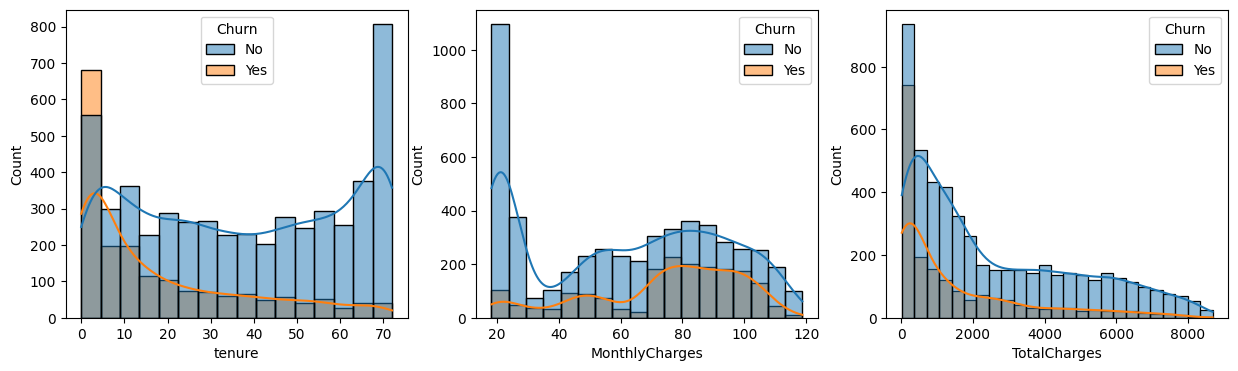

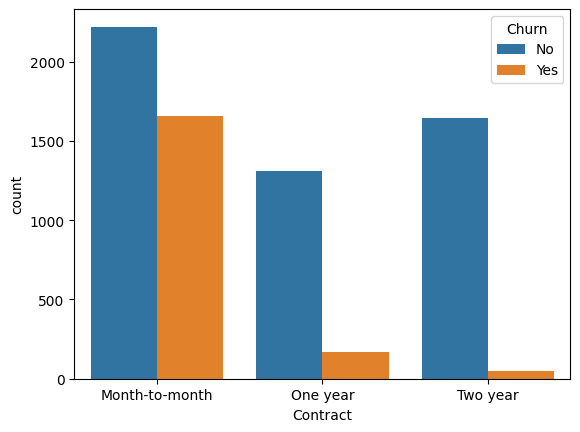

In [31]:
# Missing / bad values: TotalCharges is stored as text with blanks (new customers, tenure = 0)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print(df.isna().sum()[df.isna().sum()>0])
fig, ax = plt.subplots(1,3, figsize=(15,4))
for a, c in zip(ax, ['tenure','MonthlyCharges','TotalCharges']):
    sns.histplot(data=df, x=c, hue='Churn', kde=True, ax=a)
plt.show()
sns.countplot(x='Contract', hue='Churn', data=df); plt.show()

## 3. Data preprocessing
- Drop `customerID` (identifier, no predictive value)
- Fix `TotalCharges` (fill the 11 blanks with 0 since they are customers with tenure 0)
- Encode target: Yes=1, No=0
- One-hot encode categorical columns
- Stratified train/val/test split (70/15/15)
- Standard-scale numeric columns (fit on train only to avoid leakage)

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = df.drop(columns=['customerID'])
df['TotalCharges'] = df['TotalCharges'].fillna(0)
df['Churn'] = (df['Churn']=='Yes').astype(int)

cat_cols = [c for c in df.select_dtypes(include='object').columns]
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)
df = df.astype({c:'float32' for c in df.columns if df[c].dtype==bool})

X = df.drop(columns='Churn').astype('float32'); y = df['Churn'].values
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=42)

num_cols = ['tenure','MonthlyCharges','TotalCharges']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_val[num_cols]   = scaler.transform(X_val[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])
print(X_train.shape, X_val.shape, X_test.shape)

(4930, 30) (1056, 30) (1057, 30)


## 4. Handle class imbalance
Churners are about 26% of the data, so we use class weights instead of discarding data.

In [33]:
from sklearn.utils.class_weight import compute_class_weight
w = compute_class_weight('balanced', classes=np.array([0,1]), y=y_train)
class_weight = {0:w[0], 1:w[1]}
print(class_weight)

{0: np.float64(0.680563224737714), 1: np.float64(1.8845565749235473)}


## 5. Model architecture

In [34]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.random.set_seed(42)

model = keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(16, activation='relu'),
    layers.Dense(1, activation='sigmoid'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='binary_crossentropy',
              metrics=['accuracy', keras.metrics.AUC(name='auc'),
                       keras.metrics.Precision(name='precision'), keras.metrics.Recall(name='recall')])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,993 (19.50 KB)

 Trainable params: 4,801 (18.75 KB)

 Non-trainable params: 192 (768.00 B)

## 6. Training

In [35]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4),
]
history = model.fit(X_train.values, y_train, validation_data=(X_val.values, y_val),
                    epochs=100, batch_size=32, class_weight=class_weight,
                    callbacks=callbacks, verbose=2)

Epoch 1/100
155/155 - 9s - 56ms/step - accuracy: 0.6850 - auc: 0.7437 - loss: 0.6119 - precision: 0.4374 - recall: 0.6544 - val_accuracy: 0.7036 - val_auc: 0.8296 - val_loss: 0.5806 - val_precision: 0.4669 - val_recall: 0.8321 - learning_rate: 0.0010
Epoch 2/100
155/155 - 1s - 4ms/step - accuracy: 0.7335 - auc: 0.8169 - loss: 0.5324 - precision: 0.4985 - recall: 0.7645 - val_accuracy: 0.7225 - val_auc: 0.8352 - val_loss: 0.5531 - val_precision: 0.4864 - val_recall: 0.8286 - learning_rate: 0.0010
Epoch 3/100
155/155 - 1s - 4ms/step - accuracy: 0.7430 - auc: 0.8212 - loss: 0.5282 - precision: 0.5104 - recall: 0.7706 - val_accuracy: 0.7282 - val_auc: 0.8409 - val_loss: 0.5412 - val_precision: 0.4926 - val_recall: 0.8357 - learning_rate: 0.0010
Epoch 4/100
155/155 - 1s - 4ms/step - accuracy: 0.7418 - auc: 0.8300 - loss: 0.5160 - precision: 0.5089 - recall: 0.7691 - val_accuracy: 0.7292 - val_auc: 0.8424 - val_loss: 0.5417 - val_precision: 0.4937 - val_recall: 0.8357 - learning_rate: 0.0010

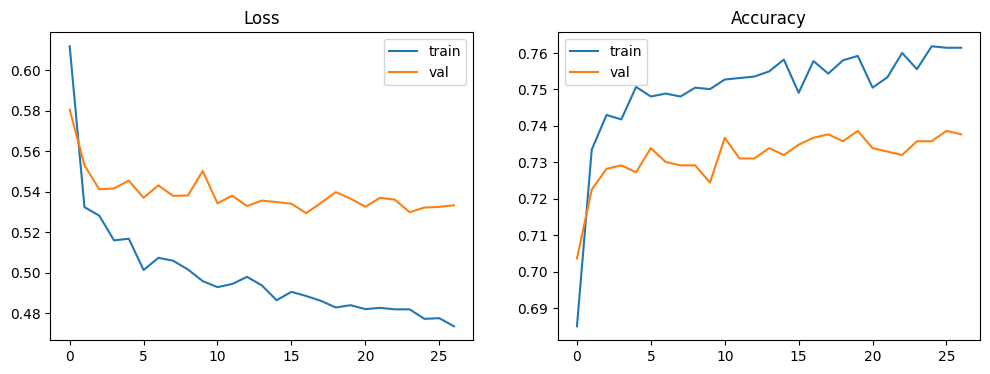

In [36]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

## 7. Evaluation on the held-out test set

34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

    No churn       0.90      0.73      0.81       776
       Churn       0.51      0.79      0.62       281

    accuracy                           0.74      1057
   macro avg       0.71      0.76      0.71      1057
weighted avg       0.80      0.74      0.76      1057

ROC-AUC: 0.8442739479766666


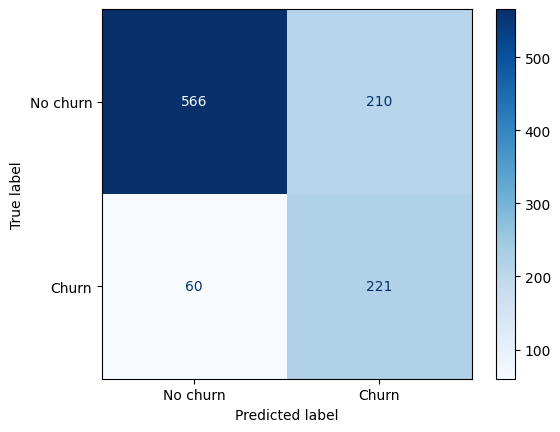

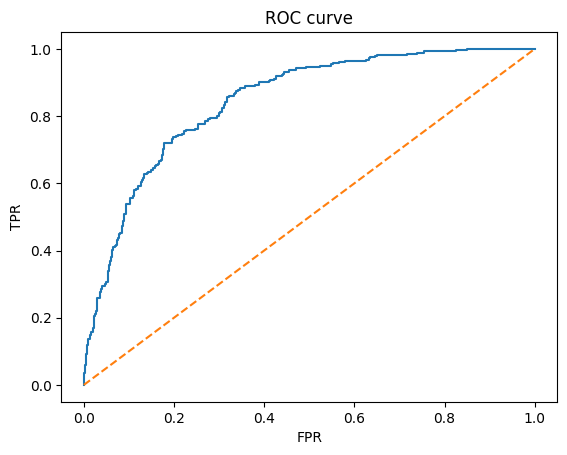

In [37]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, ConfusionMatrixDisplay

probs = model.predict(X_test.values).ravel()
preds = (probs >= 0.5).astype(int)
print(classification_report(y_test, preds, target_names=['No churn','Churn']))
print('ROC-AUC:', roc_auc_score(y_test, probs))
ConfusionMatrixDisplay(confusion_matrix(y_test, preds), display_labels=['No churn','Churn']).plot(cmap='Blues'); plt.show()
fpr, tpr, _ = roc_curve(y_test, probs); plt.plot(fpr, tpr); plt.plot([0,1],[0,1],'--'); plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title('ROC curve'); plt.show()

## 8. Baseline comparison (optional but good for the report)
Shows whether the DNN actually beats a simple model.

In [38]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000, class_weight='balanced').fit(X_train, y_train)
print('Logistic Regression AUC:', roc_auc_score(y_test, lr.predict_proba(X_test)[:,1]))
print('DNN AUC:', roc_auc_score(y_test, probs))

Logistic Regression AUC: 0.8448747110833915
DNN AUC: 0.8442739479766666


---
# PART 2 – CNN: Brain Tumor MRI Classification

## 1. Load the dataset

In [14]:
import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import kagglehub

root = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
# locate the Training / Testing folders wherever they were extracted
for dp, dn, _ in os.walk(root):
    if 'Training' in dn and 'Testing' in dn:
        DATA_DIR = dp; break
TRAIN_DIR = os.path.join(DATA_DIR, 'Training'); TEST_DIR = os.path.join(DATA_DIR, 'Testing')
print(TRAIN_DIR, os.listdir(TRAIN_DIR))
for split in (TRAIN_DIR, TEST_DIR):
    print({c: len(os.listdir(os.path.join(split,c))) for c in sorted(os.listdir(split))})

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
/kaggle/input/brain-tumor-mri-dataset/Training ['pituitary', 'notumor', 'meningioma', 'glioma']
{'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}
{'glioma': 400, 'meningioma': 400, 'notumor': 400, 'pituitary': 400}


## 2. Preprocessing
- Resize all images to 128x128 (MRI scans vary in size)
- Convert to grayscale-friendly RGB tensors, pixel values scaled to [0,1]
- 80/20 split of the Training folder into train/validation (the official Testing folder stays untouched for final evaluation)
- Data augmentation (small rotation, zoom, flip, contrast) on the training set only

In [15]:
IMG = (128,128); BATCH = 32; SEED = 42
train_ds = keras.utils.image_dataset_from_directory(TRAIN_DIR, validation_split=0.2, subset='training', seed=SEED,
                                                    image_size=IMG, batch_size=BATCH, label_mode='categorical')
val_ds   = keras.utils.image_dataset_from_directory(TRAIN_DIR, validation_split=0.2, subset='validation', seed=SEED,
                                                    image_size=IMG, batch_size=BATCH, label_mode='categorical')
test_ds  = keras.utils.image_dataset_from_directory(TEST_DIR, image_size=IMG, batch_size=BATCH,
                                                    label_mode='categorical', shuffle=False)
class_names = train_ds.class_names; print(class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Found 5600 files belonging to 4 classes.
Using 4480 files for training.
Found 5600 files belonging to 4 classes.
Using 1120 files for validation.
Found 1600 files belonging to 4 classes.
['glioma', 'meningioma', 'notumor', 'pituitary']


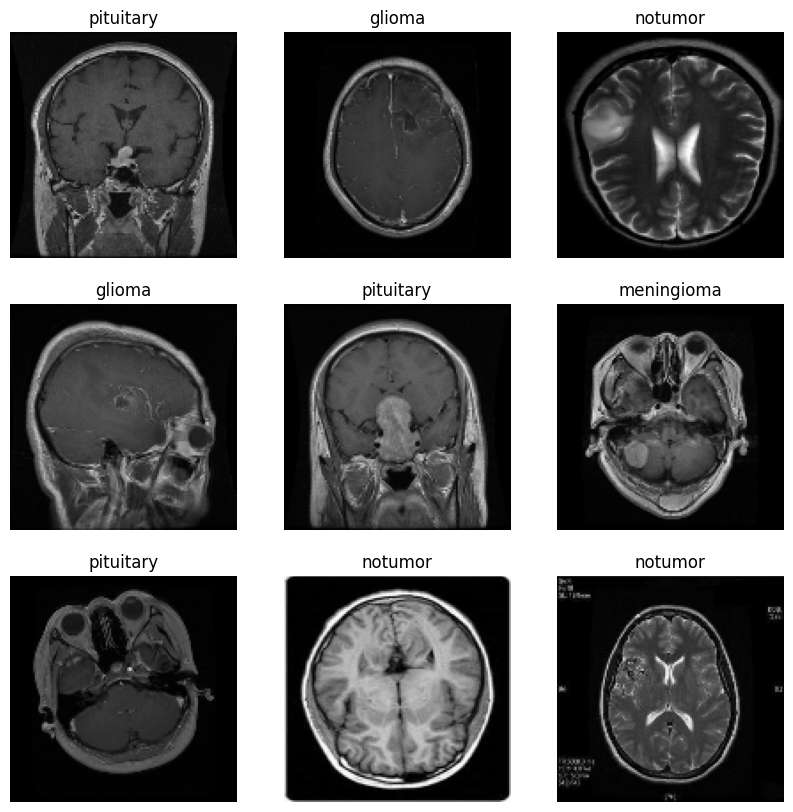

In [16]:
# Sample images
plt.figure(figsize=(10,10))
for imgs, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1); plt.imshow(imgs[i].numpy().astype('uint8'))
        plt.title(class_names[np.argmax(labels[i])]); plt.axis('off')
plt.show()

## 3. Model architecture
A custom CNN with 4 convolutional blocks (Conv-BatchNorm-ReLU-MaxPool), followed by global average pooling, a dense layer with dropout and a softmax output.

In [17]:
augment = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

def conv_block(x, f):
    x = layers.Conv2D(f, 3, padding='same', use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    return layers.MaxPooling2D()(x)

inputs = keras.Input(shape=IMG+(3,))
x = augment(inputs)
x = layers.Rescaling(1./255)(x)
for f in (32, 64, 128, 256):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation='relu')(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(len(class_names), activation='softmax')(x)
model = keras.Model(inputs, outputs)

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 423,268 (1.61 MB)

 Trainable params: 422,308 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 4. Training

In [24]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3),
    keras.callbacks.ModelCheckpoint('best_cnn.keras', monitor='val_accuracy', save_best_only=True),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=40, callbacks=callbacks)

Epoch 1/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 47ms/step - accuracy: 0.8310 - loss: 0.4381 - val_accuracy: 0.6580 - val_loss: 1.0852 - learning_rate: 2.5000e-04
Epoch 2/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - accuracy: 0.8420 - loss: 0.4205 - val_accuracy: 0.7607 - val_loss: 0.6452 - learning_rate: 2.5000e-04
Epoch 3/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8493 - loss: 0.4001 - val_accuracy: 0.7464 - val_loss: 0.8119 - learning_rate: 2.5000e-04
Epoch 4/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8547 - loss: 0.3911 - val_accuracy: 0.6911 - val_loss: 0.8786 - learning_rate: 2.5000e-04
Epoch 5/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8522 - loss: 0.3819 - val_accuracy: 0.6661 - val_loss: 1.5207 - learning_rate: 2.5000e-04
Epoch 6/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.8737 - loss: 0.3496 - val_accuracy: 0.7446 - val_loss: 0.8574 - learning_rate: 1.2500e-04
Epoch 7/40
140/140 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - acc

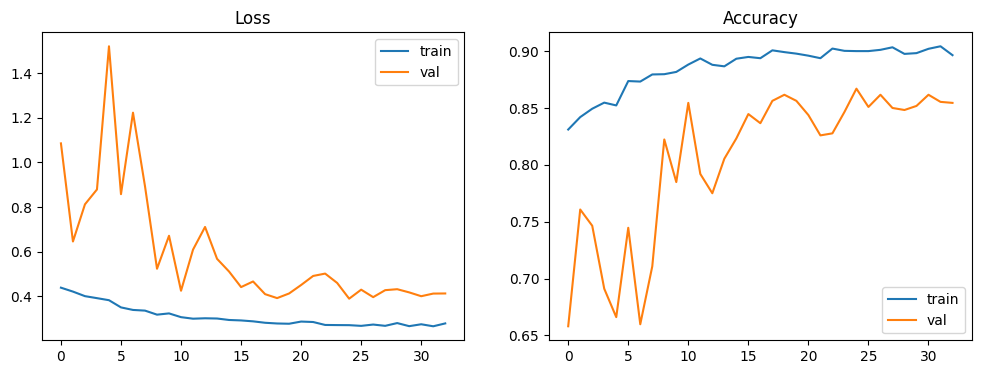

In [25]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='val'); ax[0].set_title('Loss'); ax[0].legend()
ax[1].plot(history.history['accuracy'], label='train'); ax[1].plot(history.history['val_accuracy'], label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
plt.show()

## 5. Evaluation on the official Testing set

50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.7862 - loss: 0.8442
Test accuracy: 0.7862
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
              precision    recall  f1-score   support

      glioma       0.94      0.67      0.78       400
  meningioma       0.81      0.50      0.62       400
     notumor       0.73      0.99      0.84       400
   pituitary       0.75      0.98      0.85       400

    accuracy                           0.79      1600
   macro avg       0.81      0.79      0.77      1600
weighted avg       0.81      0.79      0.77      1600



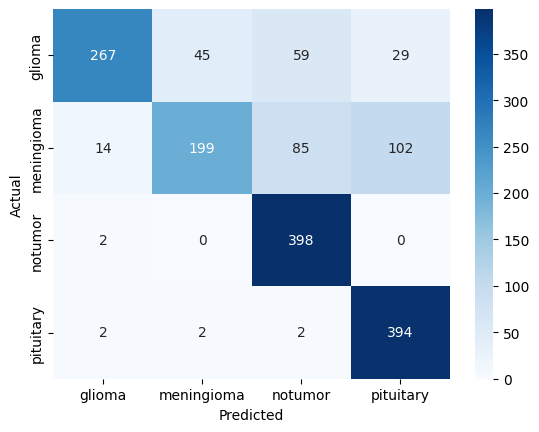

In [26]:
from sklearn.metrics import classification_report, confusion_matrix
loss, acc = model.evaluate(test_ds); print(f'Test accuracy: {acc:.4f}')

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)
print(classification_report(y_true, y_pred, target_names=class_names))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.show()

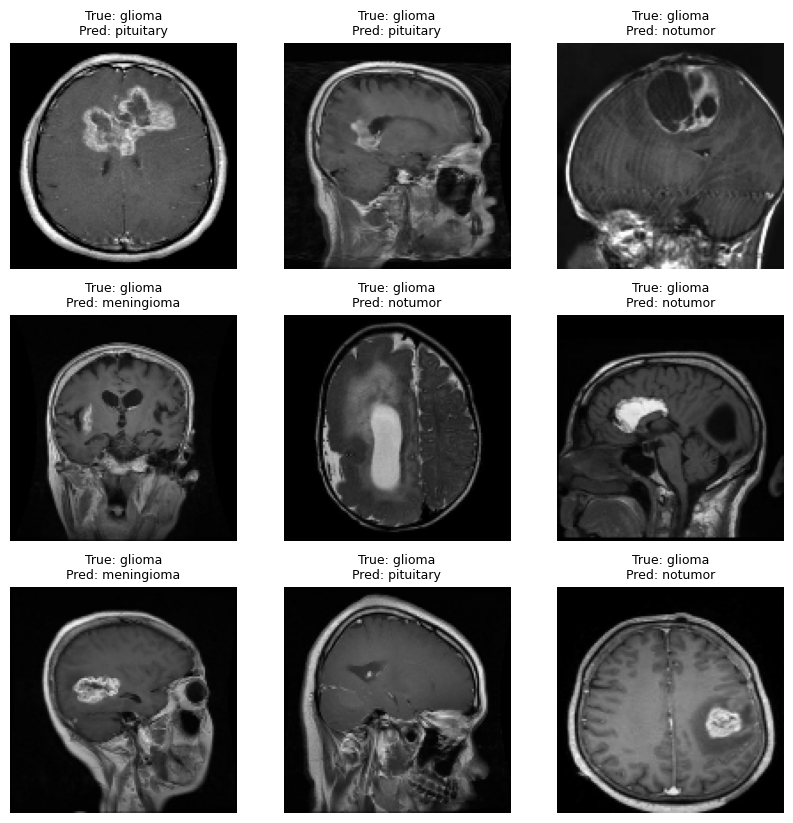

In [27]:
# Misclassified examples
imgs_all = np.concatenate([x.numpy() for x, _ in test_ds])
wrong = np.where(y_true != y_pred)[0][:9]
plt.figure(figsize=(10,10))
for i, idx in enumerate(wrong):
    plt.subplot(3,3,i+1); plt.imshow(imgs_all[idx].astype('uint8'))
    plt.title(f'True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}', fontsize=9); plt.axis('off')
plt.show()

##Transfer learning


In [28]:
base = keras.applications.MobileNetV2(input_shape=IMG+(3,), include_top=False, weights='imagenet')
base.trainable = False
inp = keras.Input(shape=IMG+(3,))
x = augment(inp)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(len(class_names), activation='softmax')(x)
tl = keras.Model(inp, out)
tl.compile(optimizer=keras.optimizers.Adam(1e-3), loss='categorical_crossentropy', metrics=['accuracy'])
tl.fit(train_ds, validation_data=val_ds, epochs=10,
       callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)])
print('Transfer-learning test accuracy:', tl.evaluate(test_ds)[1])

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.6973 - loss: 0.7698 - val_accuracy: 0.8000 - val_loss: 0.5350
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8190 - loss: 0.4701 - val_accuracy: 0.8223 - val_loss: 0.4634
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8413 - loss: 0.4051 - val_accuracy: 0.8348 - val_loss: 0.4241
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.8600 - loss: 0.3833 - val_accuracy: 0.8045 - val_loss: 0.5379
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8625 - loss: 0.3561 - val_accuracy: 0.8411 - val_loss: 0.4039
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 28ms/step - accuracy: 0.8748 - loss: 0.3385 - val_accuracy: 0.8545 - val_loss: 0.3625
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 26ms/step - accuracy: 0.8801 - loss: 0.3090 - val_accuracy: 0.8536 - val_loss: 0.3708
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.8779 - loss: 0.3100 - val_acc